# Cobertura de médico de família em Portugal Continental

**Fase 2 — Entendimento dos Dados | CRISP-DM**

Nesta fase recolhemos a fonte original, verificamos a estrutura e a qualidade dos valores e exploramos padrões que orientam o tratamento e a análise. O recorte principal continua a ser **janeiro de 2024 a junho de 2026**; o histórico bruto inclui **janeiro de 2016 a junho de 2026**.

A reorganização de 2024 e a mudança do indicador em julho de 2026 são verificações diferentes. A primeira condiciona a comparação territorial; a segunda impede ligar os indicadores antigos e novos como uma série contínua.

Este notebook faz parte da estrutura do projeto: `notebooks/`, `src/`, `data/input/`, `data/output/`, `data/analytics/`, `data/models/`, `docs/` e `media/`. Os gráficos e tabelas desta fase ficam em `data/analytics/`. O dataset tratado será produzido na fase 3.

**Execução:** guardar o notebook em `notebooks/` e o módulo `recolha_sns.py` em `src/`, como no pacote fornecido. Usar o kernel Python do VS Code e executar as células por ordem. Bibliotecas: pandas e matplotlib. Se faltarem, instalar no kernel com `%pip install pandas matplotlib`.

[Enquadramento e hipóteses](01_business_understanding.ipynb)

## 1. Configuração e fonte

O código identifica a raiz do projeto, quer o kernel esteja em `notebooks/` quer esteja na raiz. Os caminhos não dependem do computador em que o projeto é executado.

Fonte: [tabela do indicador antigo](https://transparencia.sns.gov.pt/explore/assets/utentes-inscritos-em-cuidados-de-saude-primarios/view/). O [novo indicador](https://transparencia.sns.gov.pt/explore/assets/inscritoscuidadosdesaudeprimarios/explore/) ficará separado desta análise.

In [1]:
import json
import sys
from html.parser import HTMLParser
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

atual = Path.cwd().resolve()
raiz = next(
    (
        p
        for p in [atual, *atual.parents]
        if (p / "notebooks").is_dir() and (p / "data").is_dir()
    ),
    None,
)
if raiz is None:
    raise FileNotFoundError(
        "Abrir a pasta do projeto, com notebooks/ e data/, antes de executar."
    )

PASTA_INPUT = raiz / "data" / "input"
PASTA_ANALYTICS = raiz / "data" / "analytics"
PASTA_DOCS = raiz / "docs"
for pasta in [PASTA_INPUT, PASTA_ANALYTICS, PASTA_DOCS]:
    pasta.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(raiz / "src"))
from recolha_sns import recolher_historico

INICIO = pd.Timestamp("2024-01-01")
FIM = pd.Timestamp("2026-06-01")
COL_TOTAL = "utentes_inscritos_csp"
COL_COM = "total_utentes_com_mdf_atribuido"
COL_SEM = "total_utentes_sem_mdf_atribuido"
COL_PCT = "total_utentes_sem_mdf_atribuido0"
COL_OPCAO = "total_utentes_sem_mdf_atribuido_por_opcao"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
    }
)


def guardar_tabela(tabela, nome):
    tabela.to_csv(PASTA_ANALYTICS / nome, index=False, encoding="utf-8-sig")


def mostrar_grafico(figura, nome):
    figura.tight_layout()
    figura.savefig(PASTA_ANALYTICS / nome, dpi=170, bbox_inches="tight")
    plt.show()
    plt.close(figura)


print("Raiz encontrada:", raiz)
print("Resultados desta fase: data/analytics/")

Raiz encontrada: C:\Users\Tiago\Documents\trabalho2
Resultados desta fase: data/analytics/


## 2. Recolha e preservação

A exportação CSV recolhe o histórico completo sem um filtro temporal. O módulo guarda os bytes originais, os metadados publicados pela API e a data e parâmetros da recolha.

Quando os três ficheiros já existem, são reutilizados e as somas de verificação são conferidas. Executar o notebook não substitui a recolha por dados eventualmente revistos. O pacote inclui uma recolha real para permitir reproduzir os mesmos resultados; para fazer uma nova recolha, escolher outra pasta de entrada e conservar a anterior.

In [2]:
ficheiro_bruto, metadados_api, recolha = recolher_historico(PASTA_INPUT)
print("Fonte:", recolha["dataset"])
print("Data da recolha (UTC):", recolha["recolhido_em_utc"])
print("Estado HTTP do CSV na recolha:", recolha["estado_http_csv"])
print("Bytes guardados:", recolha["bytes_csv"])
print("Ficheiro: data/input/", ficheiro_bruto.name, sep="")

metas = metadados_api["metas"]
print("Periodicidade declarada:", metas["dcat"].get("accrualperiodicity"))
print("Cobertura temporal declarada:", metas["dcat"].get("temporal"))
print("Registos declarados pela fonte:", metas["default"].get("records_count"))


class TextoHTML(HTMLParser):
    def __init__(self):
        super().__init__()
        self.partes = []

    def handle_data(self, texto):
        self.partes.append(texto.strip())


parser = TextoHTML()
parser.feed(metas["default"].get("description", ""))
descricao_fonte = " ".join(x for x in parser.partes if x)
print("Descrição e alertas publicados pela fonte:")
print(descricao_fonte)

Fonte: utentes-inscritos-em-cuidados-de-saude-primarios
Data da recolha (UTC): 2026-10-13T17:20:14.911883+00:00
Estado HTTP do CSV na recolha: 200
Bytes guardados: 764093
Ficheiro: data/input/utentes_csp_historico_bruto.csv
Periodicidade declarada: Mensal
Cobertura temporal declarada: janeiro 2016 a junho 2026
Registos declarados pela fonte: 6450
Descrição e alertas publicados pela fonte:
Monitoriza a informação dos utentes inscritos por Região de Saúde e a nível Nacional (Portugal Continental), para utentes inscritos em unidades funcionais dos ACES/ULS. O BI do indicador está disponível em https://sdm.min-saude.pt/bi.aspx?id=2&cl . Observações: Não inclui informação referente a utentes inscritos em "postos empresa" . Alerta: O indicador foi descontinuado devido à alteração das regras de qualificação dos registos, inscrição em cuidados de saúde primários e elegibilidade para médico de família no RNU, em aplicação a partir de julho de 2026. Estas alterações introduzem uma quebra na séri

### Leitura da fonte

O campo `periodo` tem referência mensal. As contagens de inscritos e as percentagens de atribuição de médico representam a situação nesse mês. As taxas de utilização de consultas são identificadas como indicadores de **um ano**, cuja definição da janela ainda tem de ser confirmada.

A descrição da fonte alerta para a descontinuação do indicador e a quebra em julho de 2026. Não será usada a nova série para prolongar este histórico. A frequência mensal também não garante que os valores fossem publicados imediatamente no fim de cada mês.

## 3. Estrutura e dicionário dos dados

O CSV é lido inicialmente como texto. Isso preserva a representação dos campos no DataFrame de origem. A conversão de datas e números será feita numa cópia de exploração, sem alterar o ficheiro ou o DataFrame bruto.

In [3]:
df_bruto = pd.read_csv(ficheiro_bruto, sep=";", encoding="utf-8-sig", dtype="string")
campos_necessarios = [
    "periodo",
    "ars",
    "aces",
    COL_TOTAL,
    COL_COM,
    COL_SEM,
    COL_PCT,
    COL_OPCAO,
]
faltam = sorted(set(campos_necessarios) - set(df_bruto.columns))
if faltam:
    raise ValueError(f"Faltam campos necessários ou o esquema mudou: {faltam}")

campos = metadados_api["fields"]
dicionario = pd.DataFrame(
    [
        {
            "campo": c["name"],
            "rotulo_fonte": c.get("label_pt", c.get("label", c["name"])),
            "tipo_fonte": c["type"],
            "presente_no_csv": c["name"] in df_bruto.columns,
        }
        for c in campos
    ]
)
guardar_tabela(dicionario, "02_dicionario_fonte.csv")
print("Dimensão do histórico:", df_bruto.shape)
display(dicionario)
display(df_bruto[campos_necessarios].head(5))

Dimensão do histórico: (6450, 13)


,campo,rotulo_fonte,tipo_fonte,presente_no_csv
0,periodo,Período,date,True
1,ars,ARS/Região,text,True
2,aces,ACES/ULS,text,True
3,localizacao_geografica,Localização Geográfica,geo_point_2d,True
4,utentes_inscritos_csp,Utentes Inscritos CSP,int,True
5,total_utentes_com_mdf_atribuido,Total Utentes com MdF atribuído,int,True
6,total_utentes_com_mdf_atribuido0,% Total Utentes com MdF atribuído,double,True
7,total_utentes_sem_mdf_atribuido,Total Utentes sem MdF Atribuído,int,True
8,total_utentes_sem_mdf_atribuido0,% Total Utentes sem MdF Atribuído,double,True
9,total_utentes_sem_mdf_atribuido_por_opcao,Total Utentes sem MdF Atribuído por Opção,int,True


,periodo,ars,aces,utentes_inscritos_csp,total_utentes_com_mdf_atribuido,total_utentes_sem_mdf_atribuido,total_utentes_sem_mdf_atribuido0,total_utentes_sem_mdf_atribuido_por_opcao
0,2016-01,Alentejo,ACES Alentejo Central,166863,165494,1287,0.77,82
1,2016-01,Alentejo,ACES Alentejo Litoral,92693,70120,22533,24.31,40
2,2016-01,Alentejo,ACES Baixo Alentejo,125192,121945,3109,2.48,138
3,2016-01,Alentejo,ACES São Mamede,117937,109694,8148,6.91,95
4,2016-01,Algarve,ACES Algarve Barlavento,159567,104459,54259,34.0,849


### Indicadores usados

- `utentes_inscritos_csp`: total de inscritos.
- `total_utentes_sem_mdf_atribuido`: categoria de inscritos sem médico, apresentada separadamente da categoria por opção.
- `total_utentes_sem_mdf_atribuido0`: percentagem correspondente. **12.8 significa 12,8%.**
- `total_utentes_sem_mdf_atribuido_por_opcao`: categoria por opção, que permanece separada.
- `ars` e `aces`: região de saúde e designação da unidade publicadas pela fonte.

As coordenadas geográficas indicam uma localização de referência; não delimitam o território da unidade. A H4 usa a região de saúde e a dimensão das unidades, sem inferir categorias como urbano/rural a partir de um ponto no mapa.

In [4]:
df_exploracao = df_bruto.copy(deep=True)
df_exploracao["mes"] = pd.to_datetime(
    df_bruto["periodo"], format="%Y-%m", errors="coerce"
)
colunas_numericas = [
    c["name"]
    for c in campos
    if c["type"] in ["int", "double"] and c["name"] in df_bruto.columns
]
falhas_conversao = {}
for coluna in colunas_numericas:
    convertida = pd.to_numeric(df_bruto[coluna], errors="coerce")
    falhas_conversao[coluna] = int((df_bruto[coluna].notna() & convertida.isna()).sum())
    df_exploracao[coluna] = convertida

perfil = pd.DataFrame(
    {
        "campo": df_bruto.columns,
        "em_falta": df_bruto.isna().sum().values,
        "valores_distintos": df_bruto.nunique(dropna=True).values,
        "espacos_laterais": [
            (df_bruto[c].notna() & (df_bruto[c] != df_bruto[c].str.strip())).sum()
            for c in df_bruto.columns
        ],
    }
)
guardar_tabela(perfil, "02_perfil_colunas.csv")
display(perfil)
print("Falhas de conversão numérica:", falhas_conversao)
print("Datas inválidas:", df_exploracao["mes"].isna().sum())

,campo,em_falta,valores_distintos,espacos_laterais
0,periodo,0,126,0
1,ars,0,5,0
2,aces,0,96,0
3,localizacao_geografica,0,106,0
4,utentes_inscritos_csp,0,6317,0
5,total_utentes_com_mdf_atribuido,0,6312,0
6,total_utentes_com_mdf_atribuido0,0,2469,0
7,total_utentes_sem_mdf_atribuido,0,5580,0
8,total_utentes_sem_mdf_atribuido0,0,2435,0
9,total_utentes_sem_mdf_atribuido_por_opcao,0,1508,0


Falhas de conversão numérica: {'utentes_inscritos_csp': 0, 'total_utentes_com_mdf_atribuido': 0, 'total_utentes_com_mdf_atribuido0': 0, 'total_utentes_sem_mdf_atribuido': 0, 'total_utentes_sem_mdf_atribuido0': 0, 'total_utentes_sem_mdf_atribuido_por_opcao': 0, 'total_utentes_sem_mdf_atribuido_por_opcao0': 0, 'taxa_de_utilizacao_consultas_medicas_1_ano_todos_os_utentes': 0, 'taxa_de_utilizacao_consultas_medicas_1_ano_nos_utentes_sem_mdf': 0}
Datas inválidas: 0


## 4. Qualidade inicial dos valores

Os checks identificam problemas; não os corrigem automaticamente. Se aparecerem valores inválidos, divergências ou duplicados, será necessário investigar a fonte e documentar uma decisão na fase 3.

A soma das categorias é verificada apenas quando os três valores estão disponíveis. As diferenças entre percentagens publicadas e recalculadas são avaliadas em pontos percentuais, com tolerância de 0,01 para arredondamento.

In [5]:
chave = ["periodo", "ars", "aces"]
duplicados_exatos = int(df_bruto.duplicated().sum())
duplicados_chave = int(df_bruto.duplicated(subset=chave, keep=False).sum())
vazios = int(df_bruto.apply(lambda s: s.str.strip().eq("").fillna(False)).sum().sum())
negativos = int((df_exploracao[colunas_numericas] < 0).sum().sum())
campos_pct = [
    c
    for c in colunas_numericas
    if "atribuido0" in c or "por_opcao0" in c or "taxa" in c
]
fora_intervalo = int(
    ((df_exploracao[campos_pct] < 0) | (df_exploracao[campos_pct] > 100)).sum().sum()
)

soma_categorias = df_exploracao[[COL_COM, COL_SEM, COL_OPCAO]].sum(axis=1, min_count=3)
divergencia_total = df_exploracao[COL_TOTAL] - soma_categorias
linhas_divergentes = divergencia_total.notna() & divergencia_total.ne(0)
denominador = df_exploracao[COL_TOTAL].where(df_exploracao[COL_TOTAL] > 0)
pct_recalculada = 100 * df_exploracao[COL_SEM] / denominador
diferenca_pct = (pct_recalculada - df_exploracao[COL_PCT]).abs()

qualidade = pd.DataFrame(
    [
        ["Células em falta", int(df_bruto.isna().sum().sum())],
        ["Células com texto vazio", vazios],
        ["Linhas inteiras duplicadas", duplicados_exatos],
        ["Linhas com chave duplicada", duplicados_chave],
        ["Datas inválidas", int(df_exploracao["mes"].isna().sum())],
        ["Falhas de conversão numérica", sum(falhas_conversao.values())],
        ["Valores numéricos negativos", negativos],
        ["Percentagens fora de 0 a 100", fora_intervalo],
        [
            "Linhas com inscritos diferentes da soma das categorias",
            int(linhas_divergentes.sum()),
        ],
        [
            "Diferenças de percentagem superiores a 0,01 pp",
            int((diferenca_pct > 0.01).sum()),
        ],
        [
            "Linhas com inscritos iguais ou inferiores a zero",
            int((df_exploracao[COL_TOTAL] <= 0).sum()),
        ],
    ],
    columns=["verificacao", "ocorrencias"],
)
guardar_tabela(qualidade, "02_qualidade_inicial.csv")
display(qualidade)
print(
    "Maior diferença da percentagem recalculada:",
    round(float(diferenca_pct.max()), 6),
    "pp",
)

if duplicados_chave:
    display(
        df_bruto.loc[
            df_bruto.duplicated(subset=chave, keep=False), campos_necessarios
        ].head(10)
    )
if linhas_divergentes.any():
    display(df_bruto.loc[linhas_divergentes, campos_necessarios].head(10))

,verificacao,ocorrencias
0,Células em falta,0
1,Células com texto vazio,0
2,Linhas inteiras duplicadas,0
3,Linhas com chave duplicada,0
4,Datas inválidas,0
5,Falhas de conversão numérica,0
6,Valores numéricos negativos,0
7,Percentagens fora de 0 a 100,0
8,Linhas com inscritos diferentes da soma das ca...,0
9,"Diferenças de percentagem superiores a 0,01 pp",0


Maior diferença da percentagem recalculada: 0.004999 pp


### Interpretação da qualidade

As ocorrências acima permitem identificar a necessidade de tratamento. Mesmo que todos os checks deem zero, isso não demonstra que os territórios e as definições sejam comparáveis. A consistência numérica e a continuidade institucional são verificações diferentes.

As taxas de consultas continuam identificadas no dicionário e nos checks de intervalo, mas a relação prevista na Q5 fica pendente da confirmação do significado da janela de um ano.

## 5. Cobertura temporal e reorganização de 2024

A contagem de unidades por mês permite demonstrar com dados a mudança discutida na fase 1. A contagem não explica, sozinha, quais os territórios que foram transferidos; essa interpretação usa as fontes institucionais.

,mes,registos,unidades,regioes
0,2016-01-01,55,55,5
95,2023-12-01,55,55,5
96,2024-01-01,39,39,5
125,2026-06-01,39,39,5


Meses no histórico: 126
Meses em falta no histórico: 0
Período: 2016-01 a 2026-06


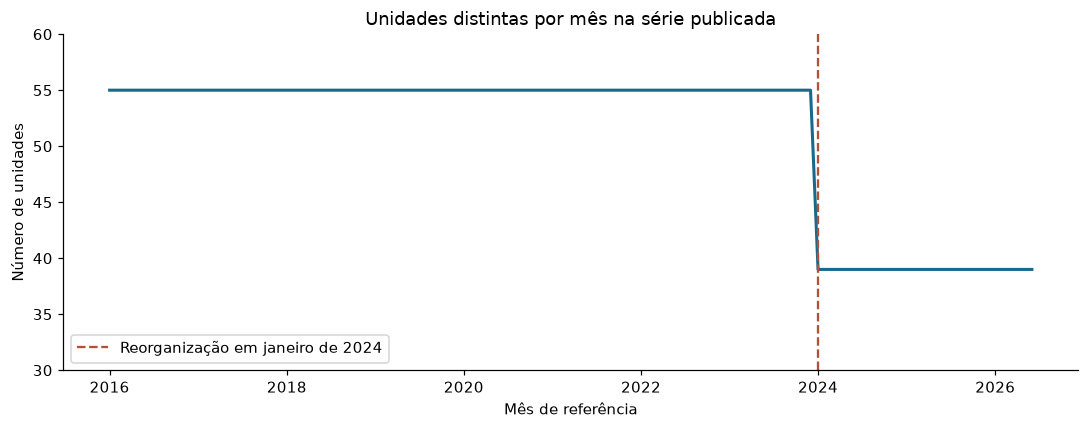

In [6]:
por_mes = (
    df_exploracao.groupby("mes")
    .agg(
        registos=("aces", "size"),
        unidades=("aces", "nunique"),
        regioes=("ars", "nunique"),
    )
    .reset_index()
    .sort_values("mes")
)
meses_esperados = pd.date_range(por_mes["mes"].min(), por_mes["mes"].max(), freq="MS")
meses_em_falta = meses_esperados.difference(pd.DatetimeIndex(por_mes["mes"]))
guardar_tabela(por_mes, "02_cobertura_por_mes.csv")
marcos = por_mes.loc[
    por_mes["mes"].isin(
        pd.to_datetime(["2016-01-01", "2023-12-01", "2024-01-01", "2026-06-01"])
    )
]
display(marcos)
print("Meses no histórico:", len(por_mes))
print("Meses em falta no histórico:", len(meses_em_falta))
print(
    "Período:",
    por_mes["mes"].min().strftime("%Y-%m"),
    "a",
    por_mes["mes"].max().strftime("%Y-%m"),
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(por_mes["mes"], por_mes["unidades"], color="#176a8b", linewidth=2)
ax.axvline(
    INICIO, color="#b45033", linestyle="--", label="Reorganização em janeiro de 2024"
)
ax.set(
    title="Unidades distintas por mês na série publicada",
    xlabel="Mês de referência",
    ylabel="Número de unidades",
)
ax.set_ylim(30, 60)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="lower left")
mostrar_grafico(fig, "02_unidades_por_mes.png")

### Interpretação da mudança

A passagem de **55 unidades em dezembro de 2023 para 39 em janeiro de 2024** coincide com a reorganização em ULS. O [Alerta de supervisão n.º 1/2024 da ERS](https://www.ers.pt/pt/atividade/supervisao/selecionar/alertas-de-supervisao/2024/alertas/alerta-de-supervis%C3%A3o-n-%C2%BA-1-2024/) descreve integração e transferência de entidades.

O [Relatório e Contas de 2023 da ULS da Região de Leiria](https://www.ulsrl.min-saude.pt/wp-content/uploads/sites/38/2025/06/RC_2023_compressed.pdf) identifica a integração do ACES de Pinhal Litoral e de centros de saúde de outros ACES. Uma alteração dos inscritos nesta transição não deve ser interpretada automaticamente como mudança no mesmo território.

**Consequência:** manter o recorte principal de 2024 a junho de 2026, sem reconstruir automaticamente as séries anteriores das atuais ULS. Os dados anteriores são preservados e a exclusão será implementada e documentada na fase 3.

## 6. Continuidade das unidades dentro do recorte

O recorte abaixo é uma **vista exploratória**. Não é ainda o dataset tratado definitivo. É usada para investigar o período acordado, mantendo o histórico original intacto.

In [7]:
vista = df_exploracao.loc[df_exploracao["mes"].between(INICIO, FIM)].copy()
meses_recorte = pd.date_range(INICIO, FIM, freq="MS")
cobertura_unidades = (
    vista.groupby(["ars", "aces"])
    .agg(
        primeiro_mes=("mes", "min"),
        ultimo_mes=("mes", "max"),
        meses_presentes=("mes", "nunique"),
    )
    .reset_index()
)
cobertura_unidades["meses_esperados"] = len(meses_recorte)
cobertura_unidades["meses_ausentes"] = (
    len(meses_recorte) - cobertura_unidades["meses_presentes"]
)
guardar_tabela(cobertura_unidades, "02_continuidade_unidades_recorte.csv")

print("Registos no histórico:", len(df_bruto))
print("Registos na vista de 2024 a junho de 2026:", len(vista))
print("Registos fora da vista:", len(df_bruto) - len(vista))
print("Designações diferentes no recorte:", vista["aces"].nunique())
display(cobertura_unidades.loc[cobertura_unidades["meses_ausentes"] > 0])
display(vista.groupby("mes").size().rename("registos").reset_index().tail())

Registos no histórico: 6450
Registos na vista de 2024 a junho de 2026: 1170
Registos fora da vista: 5280
Designações diferentes no recorte: 40


,ars,aces,primeiro_mes,ultimo_mes,meses_presentes,meses_esperados,meses_ausentes
34,Norte,CSP da ULS Póvoa Varzim / Vila Conde,2024-01-01,2026-02-01,26,30,4
35,Norte,CSP da ULS Póvoa Varzim / Vila do Conde,2026-03-01,2026-06-01,4,30,26


,mes,registos
25,2026-02-01,39
26,2026-03-01,39
27,2026-04-01,39
28,2026-05-01,39
29,2026-06-01,39


### Alteração de designação a verificar

Na recolha fornecida, aparecem duas designações: **CSP da ULS Póvoa Varzim / Vila Conde** até fevereiro de 2026 e **CSP da ULS Póvoa Varzim / Vila do Conde** a partir de março de 2026.

A diferença sugere uma alteração de escrita, mas isso ainda não prova que o território é o mesmo. A correspondência fica pendente de validação na fase 3. Não serão fundidas as designações apenas porque são parecidas.

Nas comparações de evolução por unidade abaixo, serão usadas provisoriamente apenas as designações presentes nos 30 meses. Isso evita misturar nomes ainda não harmonizados. Os rankings do último mês e as somas regionais usam os registos disponíveis desse mês, sem duplicar a unidade.

In [8]:
nomes_incompletos = cobertura_unidades.loc[
    cobertura_unidades["meses_ausentes"] > 0, "aces"
]
display(
    vista.loc[
        vista["aces"].isin(nomes_incompletos),
        ["periodo", "ars", "aces", COL_TOTAL, COL_SEM],
    ]
    .groupby("aces")
    .head(2)
)

chaves_completas = cobertura_unidades.loc[
    cobertura_unidades["meses_ausentes"] == 0, ["ars", "aces"]
]
vista_completa = vista.merge(
    chaves_completas, on=["ars", "aces"], how="inner", validate="many_to_one"
)
print(
    "Designações com os 30 meses, usadas na evolução exploratória:",
    len(chaves_completas),
)
print("Registos dessa comparação:", len(vista_completa))

,periodo,ars,aces,utentes_inscritos_csp,total_utentes_sem_mdf_atribuido
5314,2024-01,Norte,CSP da ULS Póvoa Varzim / Vila Conde,156939,3406
5353,2024-02,Norte,CSP da ULS Póvoa Varzim / Vila Conde,156951,2441
6328,2026-03,Norte,CSP da ULS Póvoa Varzim / Vila do Conde,160061,2036
6367,2026-04,Norte,CSP da ULS Póvoa Varzim / Vila do Conde,160479,2365


Designações com os 30 meses, usadas na evolução exploratória: 38
Registos dessa comparação: 1140


## 7. Exploração da dimensão e cobertura — Q1, Q2 e H1

No último mês da série, comparar os rankings por contagem e por percentagem. A comparação usa todas as unidades do mesmo mês; os nomes não são alterados nos dados. A abreviação dos rótulos serve apenas para os gráficos.

,ars,aces,utentes_inscritos_csp,total_utentes_sem_mdf_atribuido,total_utentes_sem_mdf_atribuido0
6425,Lisboa e Vale do Tejo,CSP da ULS Amadora / Sintra,582385,194681,33.43
6415,Algarve,CSP da ULS Algarve,561074,122390,21.81
6433,Lisboa e Vale do Tejo,CSP da ULS Oeste,260064,121299,46.64
6428,Lisboa e Vale do Tejo,CSP da ULS Estuário do Tejo,248386,118579,47.74
6434,Lisboa e Vale do Tejo,CSP da ULS Santa Maria,360466,116632,32.36
6435,Lisboa e Vale do Tejo,CSP da ULS São José,452801,116265,25.68
6427,Lisboa e Vale do Tejo,CSP da ULS Arrábida,257946,102542,39.75
6426,Lisboa e Vale do Tejo,CSP da ULS Arco Ribeirinho,250308,95261,38.06
6422,Centro,CSP da ULS Região de Leiria,419933,86280,20.55
6431,Lisboa e Vale do Tejo,CSP da ULS Loures / Odivelas,245449,83311,33.94


,ars,aces,utentes_inscritos_csp,total_utentes_sem_mdf_atribuido,total_utentes_sem_mdf_atribuido0
6428,Lisboa e Vale do Tejo,CSP da ULS Estuário do Tejo,248386,118579,47.74
6433,Lisboa e Vale do Tejo,CSP da ULS Oeste,260064,121299,46.64
6427,Lisboa e Vale do Tejo,CSP da ULS Arrábida,257946,102542,39.75
6426,Lisboa e Vale do Tejo,CSP da ULS Arco Ribeirinho,250308,95261,38.06
6431,Lisboa e Vale do Tejo,CSP da ULS Loures / Odivelas,245449,83311,33.94
6432,Lisboa e Vale do Tejo,CSP da ULS Médio Tejo,185232,62450,33.71
6425,Lisboa e Vale do Tejo,CSP da ULS Amadora / Sintra,582385,194681,33.43
6434,Lisboa e Vale do Tejo,CSP da ULS Santa Maria,360466,116632,32.36
6414,Alentejo,CSP da ULS Litoral Alentejano,107563,34459,32.04
6435,Lisboa e Vale do Tejo,CSP da ULS São José,452801,116265,25.68


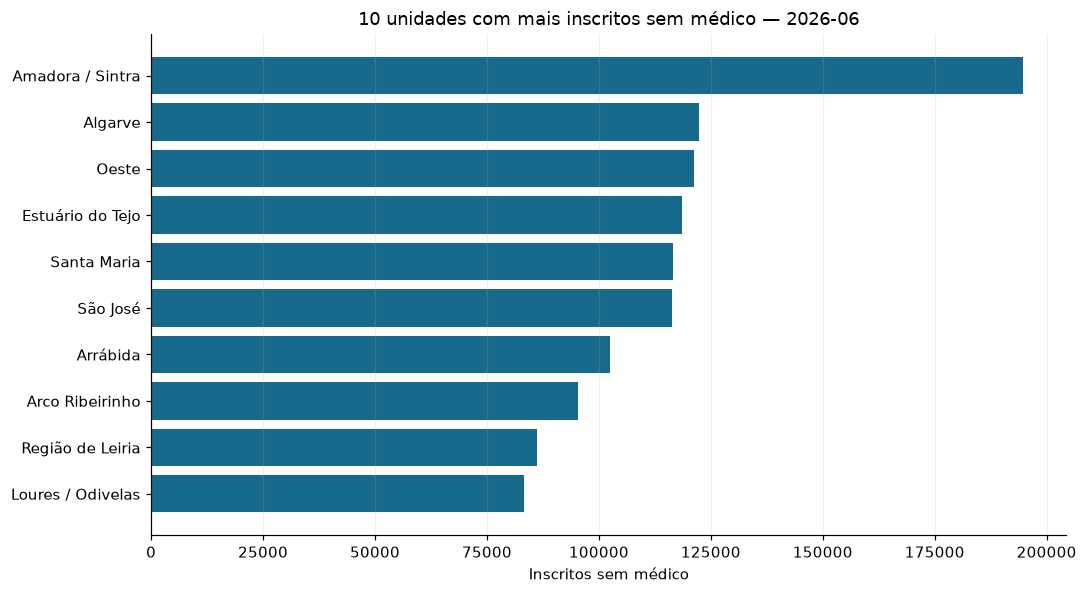

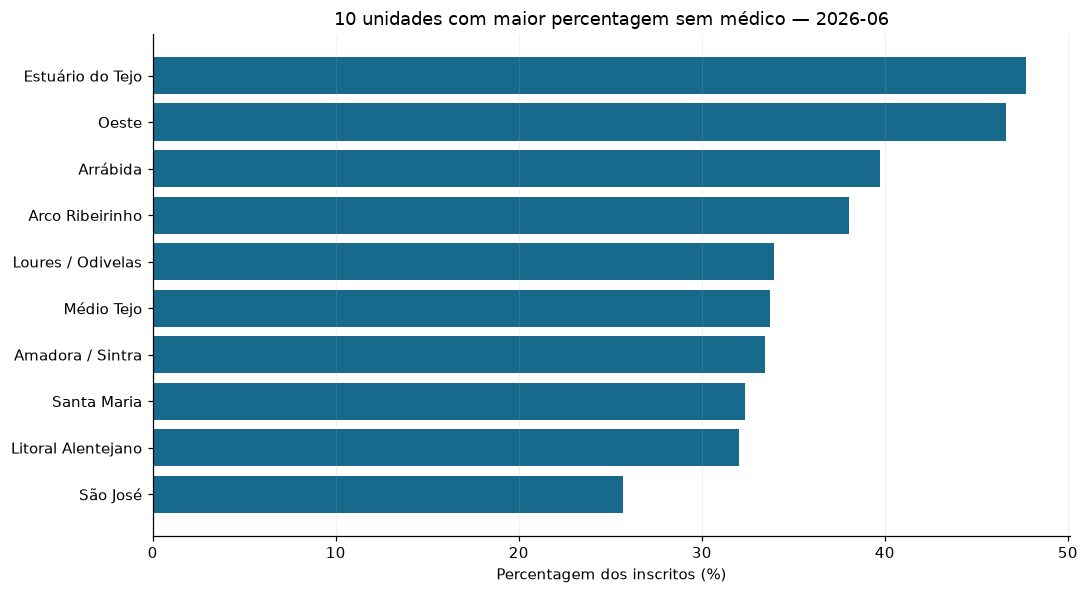

Correlação de Spearman entre os rankings: 0.938
Unidades com posições de ranking diferentes: 35 de 39
Maior número: CSP da ULS Amadora / Sintra — 194681 inscritos sem médico.
Maior percentagem: CSP da ULS Estuário do Tejo — 47.74 %.
H1: os rankings divergem nesta fotografia mensal.


In [9]:
ultimo_mes = vista["mes"].max()
ultimo = vista.loc[vista["mes"] == ultimo_mes].copy()
ranking_numero = ultimo.sort_values(COL_SEM, ascending=False)
ranking_percentagem = ultimo.sort_values(COL_PCT, ascending=False)
guardar_tabela(
    ranking_numero[["periodo", "ars", "aces", COL_TOTAL, COL_SEM, COL_PCT]],
    "02_ranking_numero.csv",
)
guardar_tabela(
    ranking_percentagem[["periodo", "ars", "aces", COL_TOTAL, COL_SEM, COL_PCT]],
    "02_ranking_percentagem.csv",
)
display(ranking_numero[["ars", "aces", COL_TOTAL, COL_SEM, COL_PCT]].head(10))
display(ranking_percentagem[["ars", "aces", COL_TOTAL, COL_SEM, COL_PCT]].head(10))

for coluna, titulo, eixo, nome in [
    (
        COL_SEM,
        "10 unidades com mais inscritos sem médico",
        "Inscritos sem médico",
        "02_top10_numero.png",
    ),
    (
        COL_PCT,
        "10 unidades com maior percentagem sem médico",
        "Percentagem dos inscritos (%)",
        "02_top10_percentagem.png",
    ),
]:
    top = ultimo.nlargest(10, coluna).sort_values(coluna)
    rotulos = top["aces"].str.replace("CSP da ULS ", "", regex=False)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.barh(rotulos, top[coluna], color="#176a8b")
    ax.set(title=f"{titulo} — {ultimo_mes:%Y-%m}", xlabel=eixo)
    ax.grid(axis="x", alpha=0.18)
    mostrar_grafico(fig, nome)

rank_num = ultimo[COL_SEM].rank(ascending=False, method="average")
rank_pct = ultimo[COL_PCT].rank(ascending=False, method="average")
correlacao_rankings = rank_num.corr(rank_pct)
print("Correlação de Spearman entre os rankings:", round(correlacao_rankings, 3))
print(
    "Unidades com posições de ranking diferentes:",
    int(rank_num.ne(rank_pct).sum()),
    "de",
    len(ultimo),
)
lider_numero = ranking_numero.iloc[0]
lider_percentagem = ranking_percentagem.iloc[0]
print(
    "Maior número:",
    lider_numero["aces"],
    "—",
    int(lider_numero[COL_SEM]),
    "inscritos sem médico.",
)
print(
    "Maior percentagem:",
    lider_percentagem["aces"],
    "—",
    round(float(lider_percentagem[COL_PCT]), 2),
    "%.",
)
print(
    "H1:",
    "os rankings divergem nesta fotografia mensal."
    if rank_num.ne(rank_pct).any()
    else "os rankings coincidem nesta fotografia mensal.",
)

### Interpretação da H1

Rankings diferentes mostram que dimensão e cobertura proporcional não são a mesma leitura do problema. A correlação dos rankings resume a sua proximidade; não mede causalidade nem permite escolher automaticamente qual das duas medidas é mais importante.

A primeira tabela responde à dimensão absoluta; a segunda à proporção de inscritos afetados. Os empates são tratados com posições médias.

## 8. Evolução por unidade e região — Q3, Q4 e H2

As variações por unidade usam apenas as designações presentes nos 30 meses nesta exploração. A visão regional soma contagens e inscritos antes de calcular a percentagem. Não usa médias simples das percentagens das unidades.

,ars,aces,utentes_inscritos_csp_inicio,total_utentes_sem_mdf_atribuido0_inicio,utentes_inscritos_csp_fim,total_utentes_sem_mdf_atribuido0_fim,variacao_pct_sem_medico_pp,variacao_inscritos_pct
8,Centro,CSP da ULS Cova da Beira,85716,27.94,86351,12.85,-15.09,0.740819
5,Centro,CSP da ULS Baixo Mondego,108821,10.37,111771,0.82,-9.55,2.710874
11,Centro,CSP da ULS Região de Leiria,402953,28.48,419933,20.55,-7.93,4.213891
7,Centro,CSP da ULS Coimbra,407091,10.91,417197,4.56,-6.35,2.482492
18,Lisboa e Vale do Tejo,CSP da ULS Lezíria,201170,23.82,206880,17.67,-6.15,2.838395


,ars,aces,utentes_inscritos_csp_inicio,total_utentes_sem_mdf_atribuido0_inicio,utentes_inscritos_csp_fim,total_utentes_sem_mdf_atribuido0_fim,variacao_pct_sem_medico_pp,variacao_inscritos_pct
16,Lisboa e Vale do Tejo,CSP da ULS Arrábida,243814,26.54,257946,39.75,13.21,5.796222
3,Alentejo,CSP da ULS Litoral Alentejano,103708,23.39,107563,32.04,8.65,3.717167
21,Lisboa e Vale do Tejo,CSP da ULS Médio Tejo,180339,27.53,185232,33.71,6.18,2.713223
36,Norte,CSP da ULS Trás-os-Montes Alto Douro,261461,1.99,262296,8.03,6.04,0.319359
6,Centro,CSP da ULS Castelo Branco,101232,16.75,102522,21.67,4.92,1.274301


,mes,ars,utentes_inscritos_csp,total_utentes_sem_mdf_atribuido,pct_sem_medico
0,2024-01-01,Alentejo,502818,86258,17.154915
1,2024-01-01,Algarve,524522,110016,20.974525
2,2024-01-01,Centro,1917871,281205,14.662352
3,2024-01-01,Lisboa e Vale do Tejo,3772792,1097234,29.082812
4,2024-01-01,Norte,3779034,72987,1.931367
145,2026-06-01,Alentejo,508422,94908,18.66717
146,2026-06-01,Algarve,561074,122390,21.813522
147,2026-06-01,Centro,1906158,180947,9.49276
148,2026-06-01,Lisboa e Vale do Tejo,3930506,1179164,30.00031
149,2026-06-01,Norte,3905138,94721,2.425548


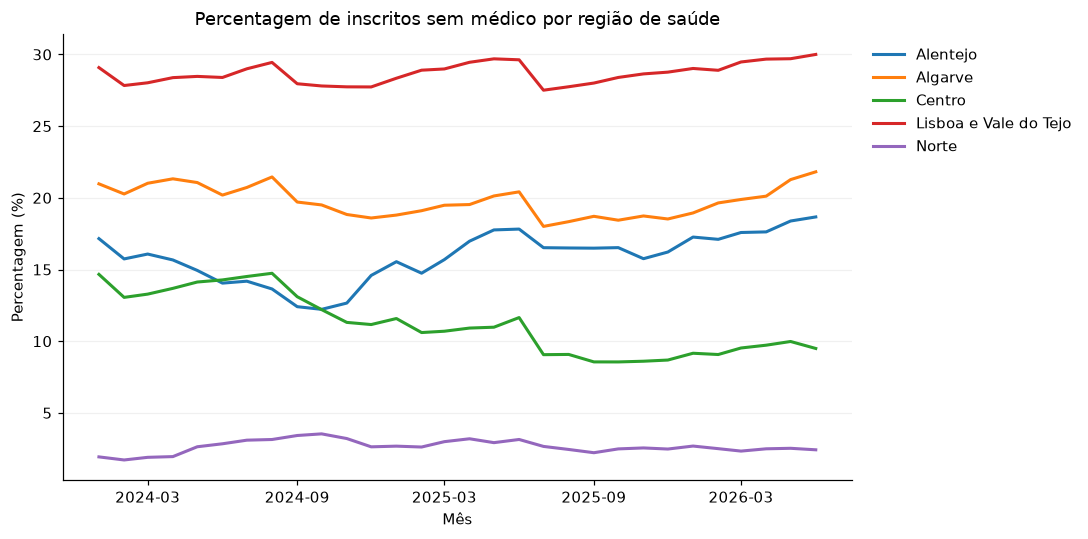

,ars,variacao_pp
0,Alentejo,1.512255
1,Algarve,0.838997
2,Centro,-5.169592
3,Lisboa e Vale do Tejo,0.917499
4,Norte,0.494181


Maior redução regional da percentagem sem médico: Centro — -5.17 pp.
H2: comparar as diferentes trajetórias e variações, sem atribuir causas aos padrões.


In [10]:
ordenada = vista_completa.sort_values(["ars", "aces", "mes"])
inicio_unidade = ordenada.groupby(["ars", "aces"]).first()[[COL_TOTAL, COL_PCT]]
fim_unidade = ordenada.groupby(["ars", "aces"]).last()[[COL_TOTAL, COL_PCT]]
evolucao = inicio_unidade.join(
    fim_unidade, lsuffix="_inicio", rsuffix="_fim"
).reset_index()
evolucao["variacao_pct_sem_medico_pp"] = (
    evolucao[f"{COL_PCT}_fim"] - evolucao[f"{COL_PCT}_inicio"]
)
evolucao["variacao_inscritos_pct"] = 100 * (
    evolucao[f"{COL_TOTAL}_fim"] / evolucao[f"{COL_TOTAL}_inicio"] - 1
)
guardar_tabela(evolucao, "02_evolucao_unidades_completas.csv")
display(evolucao.sort_values("variacao_pct_sem_medico_pp").head(5))
display(evolucao.sort_values("variacao_pct_sem_medico_pp", ascending=False).head(5))

por_regiao = (
    vista.groupby(["mes", "ars"])[[COL_TOTAL, COL_SEM]].sum(min_count=1).reset_index()
)
por_regiao["pct_sem_medico"] = 100 * por_regiao[COL_SEM] / por_regiao[COL_TOTAL]
guardar_tabela(por_regiao, "02_evolucao_regioes.csv")
display(por_regiao.loc[por_regiao["mes"].isin([INICIO, FIM])])

fig, ax = plt.subplots(figsize=(10, 5))
for regiao, dados in por_regiao.groupby("ars"):
    ax.plot(dados["mes"], dados["pct_sem_medico"], label=regiao, linewidth=2)
ax.set(
    title="Percentagem de inscritos sem médico por região de saúde",
    xlabel="Mês",
    ylabel="Percentagem (%)",
)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.grid(axis="y", alpha=0.18)
mostrar_grafico(fig, "02_evolucao_regioes.png")
variacao_regional = (
    por_regiao.loc[por_regiao["mes"] == FIM].set_index("ars")["pct_sem_medico"]
    - por_regiao.loc[por_regiao["mes"] == INICIO].set_index("ars")["pct_sem_medico"]
)
display(variacao_regional.rename("variacao_pp").reset_index())
maior_melhoria = variacao_regional.idxmin()
print(
    "Maior redução regional da percentagem sem médico:",
    maior_melhoria,
    "—",
    round(float(variacao_regional.min()), 2),
    "pp.",
)
print(
    "H2: comparar as diferentes trajetórias e variações, sem atribuir causas aos padrões."
)

### Interpretação da evolução

Uma variação positiva da percentagem sem médico indica deterioração do indicador; uma variação negativa indica melhoria. A unidade da diferença é **pontos percentuais**.

O gráfico permite comparar níveis e trajetórias regionais no recorte, sujeito à continuidade da cobertura territorial. Não demonstra que uma medida administrativa, ou a disponibilidade de profissionais, tenha causado a mudança. As unidades com designações ainda não harmonizadas ficam identificadas nas tabelas de continuidade.

## 9. Crescimento dos inscritos e variação da cobertura — H3

A comparação usa a variação relativa dos inscritos e a variação da percentagem sem médico entre os extremos do recorte, para as unidades com os 30 meses. É uma exploração de associação, não um teste do efeito causal do crescimento populacional. Inscritos também não são população residente.

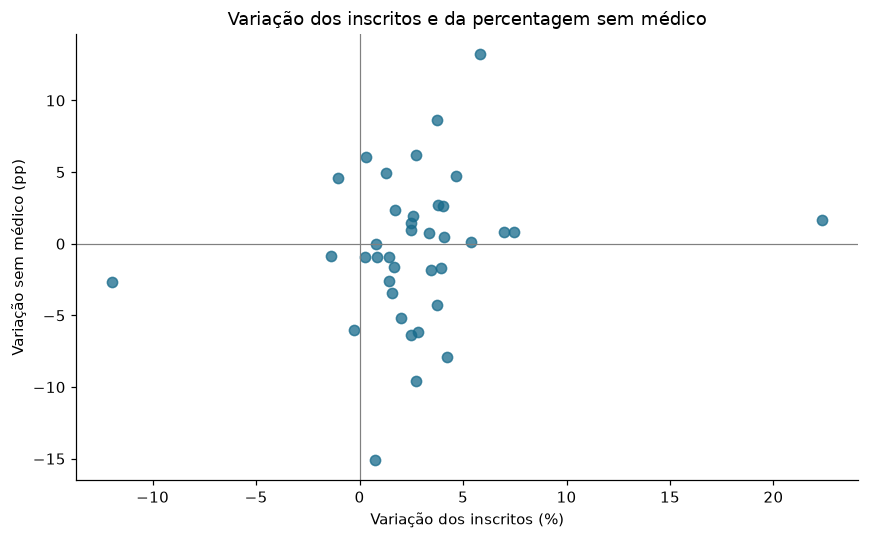

Unidades comparadas: 38
Correlação de Spearman: 0.225
O coeficiente resume a associação entre variações, mas não explica toda a dispersão do gráfico.
Não atribuir causalidade a esta associação; verificar alterações de registo e território.


In [11]:
corr_h3 = (
    evolucao["variacao_inscritos_pct"]
    .rank()
    .corr(evolucao["variacao_pct_sem_medico_pp"].rank())
)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    evolucao["variacao_inscritos_pct"],
    evolucao["variacao_pct_sem_medico_pp"],
    color="#176a8b",
    alpha=0.75,
    s=45,
)
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(
    title="Variação dos inscritos e da percentagem sem médico",
    xlabel="Variação dos inscritos (%)",
    ylabel="Variação sem médico (pp)",
)
mostrar_grafico(fig, "02_h3_variacoes.png")
print("Unidades comparadas:", len(evolucao))
print("Correlação de Spearman:", round(corr_h3, 3))
print(
    "O coeficiente resume a associação entre variações, mas não explica toda a dispersão do gráfico."
)
print(
    "Não atribuir causalidade a esta associação; verificar alterações de registo e território."
)

## 10. Comparação geográfica entre dimensões semelhantes — H4

As unidades do último mês são distribuídas por **três faixas de dimensão**, calculadas apenas a partir do total de inscritos, antes de comparar as percentagens. Os limites são comuns às regiões. Estas faixas são uma aproximação; não tornam as unidades exatamente iguais nem controlam outros fatores.

Os grupos com menos de três unidades são assinalados como pequenos. Este critério serve para expor a fragilidade da comparação, não é um limiar de significância estatística. A continuidade da diferença ao longo dos meses ficará para a análise após preparação.

,faixa_dimensao,ars,unidades,mediana_sem_medico_pct,minimo_sem_medico_pct,maximo_sem_medico_pct,inscritos_min,inscritos_max,grupo_pequeno
0,"(86350.999, 199664.0]",Alentejo,4,19.445,9.24,32.04,107563,167443,False
1,"(86350.999, 199664.0]",Centro,4,12.825,0.82,21.67,86351,140759,False
2,"(86350.999, 199664.0]",Lisboa e Vale do Tejo,1,33.71,33.71,33.71,185232,185232,True
3,"(86350.999, 199664.0]",Norte,4,1.735,0.0,2.77,126867,179250,False
4,"(199664.0, 340044.333]",Centro,1,2.22,2.22,2.22,279778,279778,True
5,"(199664.0, 340044.333]",Lisboa e Vale do Tejo,6,38.905,17.67,47.74,206880,260064,False
6,"(199664.0, 340044.333]",Norte,6,1.73,0.01,8.03,245532,336143,False
7,"(340044.333, 582385.0]",Algarve,1,21.81,21.81,21.81,561074,561074,True
8,"(340044.333, 582385.0]",Centro,3,4.94,4.56,20.55,347847,419933,False
9,"(340044.333, 582385.0]",Lisboa e Vale do Tejo,5,25.68,12.23,33.43,360466,582385,False


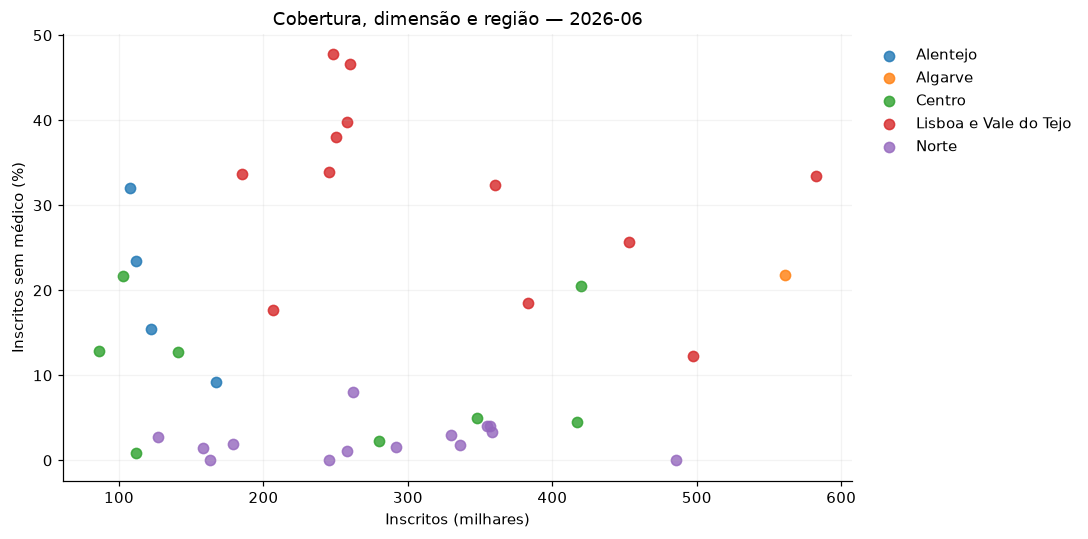

Grupos região/dimensão observados: 11
Grupos pequenos: 3
A comparação é exploratória; nem todas as regiões têm unidades em todas as faixas.


In [12]:
ultimo["faixa_dimensao"] = pd.qcut(ultimo[COL_TOTAL], q=3, duplicates="drop")
geografia = (
    ultimo.groupby(["faixa_dimensao", "ars"], observed=True)
    .agg(
        unidades=("aces", "nunique"),
        mediana_sem_medico_pct=(COL_PCT, "median"),
        minimo_sem_medico_pct=(COL_PCT, "min"),
        maximo_sem_medico_pct=(COL_PCT, "max"),
        inscritos_min=(COL_TOTAL, "min"),
        inscritos_max=(COL_TOTAL, "max"),
    )
    .reset_index()
)
geografia["grupo_pequeno"] = geografia["unidades"] < 3
guardar_tabela(geografia, "02_h4_geografia_dimensao.csv")
display(geografia)

fig, ax = plt.subplots(figsize=(10, 5))
for regiao, dados in ultimo.groupby("ars"):
    ax.scatter(dados[COL_TOTAL] / 1000, dados[COL_PCT], label=regiao, alpha=0.8, s=45)
ax.set(
    title=f"Cobertura, dimensão e região — {ultimo_mes:%Y-%m}",
    xlabel="Inscritos (milhares)",
    ylabel="Inscritos sem médico (%)",
)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.grid(alpha=0.15)
mostrar_grafico(fig, "02_h4_geografia.png")
print("Grupos região/dimensão observados:", len(geografia))
print("Grupos pequenos:", int(geografia["grupo_pequeno"].sum()))
print(
    "A comparação é exploratória; nem todas as regiões têm unidades em todas as faixas."
)

### Alcance da H4

A dispersão mostra a região, a dimensão e a percentagem no mesmo mês. A tabela permite observar diferenças dentro de faixas comuns, com os respetivos tamanhos dos grupos.

Esta evidência não permite afirmar que a região é a causa das diferenças. Grupos pequenos ou ausência de unidades de uma região numa faixa podem impedir uma comparação útil. A H4 ainda não é declarada confirmada: é necessário avaliar a continuidade dos dados e a consistência do padrão no período.

Nesta recolha, o Algarve é representado por uma única ULS. Isso limita a comparação entre unidades dentro dessa região e não equivale a observar toda a diversidade das suas localidades.

## 11. Constatações e passagem para a preparação

O resumo abaixo é gerado a partir da recolha usada. As verificações e os gráficos não substituem a interpretação nem a confirmação de correspondências territoriais. A fase 3 deverá produzir um dataset tratado com decisões rastreáveis.

In [13]:
pendencias = [
    "Confirmar a correspondência territorial das designações da ULS Póvoa Varzim / Vila Conde e Vila do Conde.",
    "Implementar D01: recorte de janeiro de 2024 a junho de 2026, com contagens antes e depois.",
    "Definir nomes de colunas, tipos e chave mensal do dataset preparado.",
    "Investigar qualquer ocorrência dos checks antes de decidir corrigir, excluir ou manter.",
    "Confirmar a definição das taxas de utilização de consultas de um ano antes de responder à Q5.",
    "Reavaliar grupos pequenos da H4 e verificar a consistência temporal da comparação geográfica.",
]
resumo = {
    "data_recolha_utc": recolha["recolhido_em_utc"],
    "linhas_historico": len(df_bruto),
    "colunas_historico": len(df_bruto.columns),
    "meses_historico": len(por_mes),
    "linhas_vista_principal": len(vista),
    "meses_vista_principal": len(meses_recorte),
    "designacoes_vista_principal": int(vista["aces"].nunique()),
    "designacoes_completas": len(chaves_completas),
    "duplicados_chave": duplicados_chave,
    "linhas_divergentes_categorias": int(linhas_divergentes.sum()),
    "correlacao_rankings_h1": round(float(correlacao_rankings), 4),
    "correlacao_variacoes_h3": round(float(corr_h3), 4),
    "grupos_pequenos_h4": int(geografia["grupo_pequeno"].sum()),
    "pendencias_fase_3": pendencias,
}
(PASTA_ANALYTICS / "02_resumo_exploracao.json").write_text(
    json.dumps(resumo, ensure_ascii=False, indent=2), encoding="utf-8"
)
nota = "# Fase 2 — Constatações e decisões pendentes\n\n"
nota += f"Recolha: {recolha['recolhido_em_utc']} (UTC).\n\n"
nota += f"Histórico: {len(df_bruto)} linhas, {len(por_mes)} meses. Vista principal: {len(vista)} linhas, {len(meses_recorte)} meses.\n\n"
nota += "A passagem de 55 para 39 unidades é evidência da mudança de estrutura em 2024. A contagem não demonstra equivalência territorial.\n\n"
nota += "Esta fase preserva o bruto e usa cópias de exploração. O dataset tratado ainda não foi produzido.\n\n"
nota += "## Pendências para a fase 3\n\n" + "\n".join(f"- {x}" for x in pendencias)
(PASTA_DOCS / "02_constatacoes_e_pendencias.md").write_text(nota, encoding="utf-8")
display(pd.DataFrame({"pendencia": pendencias}))
print(
    json.dumps(
        {k: v for k, v in resumo.items() if k != "pendencias_fase_3"},
        ensure_ascii=False,
        indent=2,
    )
)

,pendencia
0,Confirmar a correspondência territorial das de...
1,Implementar D01: recorte de janeiro de 2024 a ...
2,"Definir nomes de colunas, tipos e chave mensal..."
3,Investigar qualquer ocorrência dos checks ante...
4,Confirmar a definição das taxas de utilização ...
5,Reavaliar grupos pequenos da H4 e verificar a ...


{
  "data_recolha_utc": "2026-10-13T17:20:14.911883+00:00",
  "linhas_historico": 6450,
  "colunas_historico": 13,
  "meses_historico": 126,
  "linhas_vista_principal": 1170,
  "meses_vista_principal": 30,
  "designacoes_vista_principal": 40,
  "designacoes_completas": 38,
  "duplicados_chave": 0,
  "linhas_divergentes_categorias": 0,
  "correlacao_rankings_h1": 0.9382,
  "correlacao_variacoes_h3": 0.2249,
  "grupos_pequenos_h4": 3
}


### Resultado desta fase

- Histórico e metadados preservados em `data/input/`.
- Qualidade, cobertura temporal, continuidade de nomes e dicionário documentados em tabelas.
- Mudança de estrutura em 2024 demonstrada com dados e fontes institucionais.
- Exploração inicial de rankings, evolução, crescimento dos inscritos e comparação geográfica.
- Questões de comparabilidade e definição de indicadores explicitadas antes de produzir o dataset tratado.

Os rankings não representam uma avaliação global da qualidade das unidades. A Q5 está pendente da definição das taxas; a Q6 será avaliada na modelação e avaliação, com separação temporal e referência simples.

[Continuar para 03_data_preparation.ipynb](03_data_preparation.ipynb)